<a href="https://colab.research.google.com/github/wadeea23/ECG-Based-Heartbeat-Classification-Using-Machine-Learning/blob/main/ECG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install wfdb

In [2]:
! pip install tensorflow

In [3]:
from google.colab import drive  , files
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import zipfile

zip_path = '/content/drive/MyDrive/GA/Capstone_GA/mitdb-1.0.0.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/mitdb-1.0.0')

In [42]:
import wfdb
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Conv1D, MaxPooling1D, Flatten
import joblib
import requests
from google.colab import userdata
from collections import Counter

In [6]:
folder = '/content/mitdb-1.0.0/mit-bih-arrhythmia-database-1.0.0'

print(os.listdir(folder))

['116.xws', '122.hea', '109.dat', '123.xws', 'RECORDS', '230.hea', '123.dat', '200.dat', '117.xws', '233.xws', '228.atr', '202.dat', '209.at_', '124.dat', '223.atr', '108.atr', '220.atr', '115.xws', '213.hea', '209.xws', '106.atr', '106.xws', '213.xws', '107.hea', '101.dat', '115.atr', '116.hea', 'x_mitdb', '217.hea', '205.hea', '124.hea', '102.hea', '107.atr', '122.atr', '105.hea', '111.atr', '108.at_', '222.xws', '228.hea', '207.hea', '230.dat', '232.dat', '201.xws', '109.xws', '234.atr', '109.atr', '123.hea', '205.atr', '217.atr', '113.atr', '122.xws', '214.atr', '116.atr', '208.hea', '102.xws', '116.dat', '232.xws', '102-0.atr', '233.atr', '102.dat', '208.dat', '113.dat', '200.xws', '201.dat', '208.xws', '221.xws', '112.xws', '111.xws', '102.atr', '117.atr', '228.xws', '122.dat', '231.hea', 'mitdbdir', '223.hea', '208.atr', '202.xws', '203.hea', '124.xws', '113.xws', '214.dat', '203.dat', '209.hea', '233.dat', '205.dat', '106.hea', '222.dat', '118.xws', '112.dat', '114.xws', '203.a

In [7]:
files = os.listdir(folder)

dat_count = str(files).count('.dat')
hea_count = str(files).count('.hea')
atr_count = str(files).count('.atr')

print("DAT:", dat_count)
print("HEA:", hea_count)
print("ATR:", atr_count)

DAT: 48
HEA: 48
ATR: 49


In [8]:
all_labels = []  # عشان اجوف كل الرموز اللي في الديتا سيت و شلون اخليهم مع بعض عقب
signals = []
for file in files:  # هاي الرموز ف ديتا سيت و صنفناهم  ع حسب المعيار العلمي

    if file.endswith('.hea'):

        name = file.replace('.hea', '')
        record = wfdb.rdrecord(folder + '/' + name)
        signal = record.p_signal[:, 0]
        signals.append(signal)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        all_labels = all_labels + annotation.symbol

print("Signals:", len(signals))
print("Labels:", len(all_labels))
print("Label Types:", set(all_labels))


Signals: 48
Labels: 112647
Label Types: {'S', '!', 'E', 'Q', 'a', 'J', 'x', '[', 'e', 'f', 'V', 'N', 'L', '|', 'A', 'j', ']', 'F', '/', '+', '~', '"', 'R'}


In [9]:
# convert all clissy to aami in all records
N = all_labels.count('N') + all_labels.count('L') + all_labels.count('R') + all_labels.count('e') + all_labels.count('j')

S = all_labels.count('A') + all_labels.count('a') + all_labels.count('J') + all_labels.count('S')

V = all_labels.count('V') + all_labels.count('E')

F = all_labels.count('F')

Q = all_labels.count('/') + all_labels.count('f') + all_labels.count('Q')

print("N:", N)
print("S:", S)
print("V:", V)
print("F:", F)
print("Q:", Q)

N: 90631
S: 2781
V: 7236
F: 803
Q: 8043


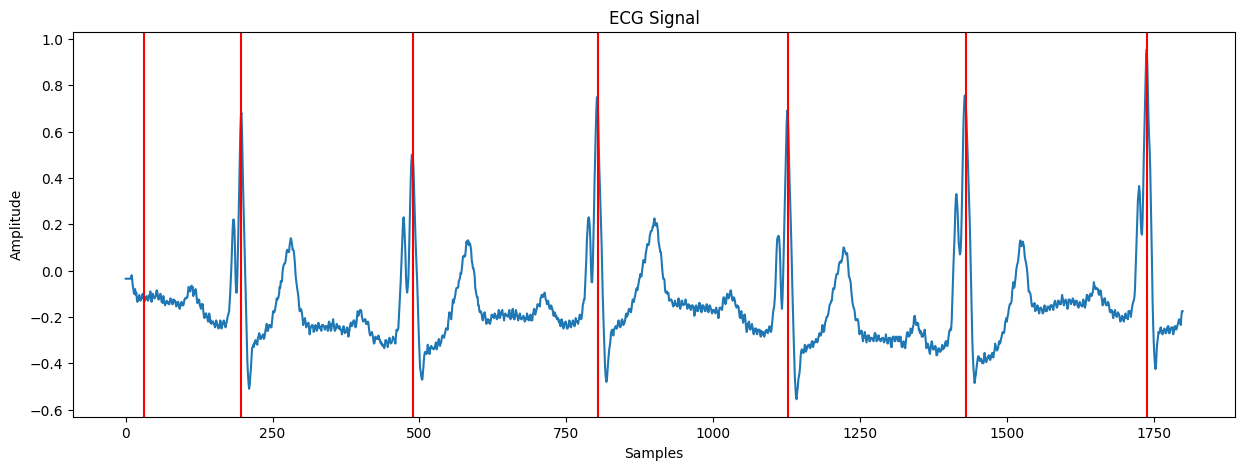

In [10]:
plt.figure(figsize=(15, 5))

plt.plot(signal[:1800]) # i choose 1800 / 360 hz = 5 sec

for peak in annotation.sample:
    if peak < 1800:
        plt.axvline(peak, color='red') # يحدد مكان النبض بالخطوط الطولية

plt.title('ECG Signal')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

In [11]:
# Heartbeat to prepare the data to train models

In [12]:
# i will prapare the data to 48 record

In [13]:
X = []
y = []

for file in files:

    if file.endswith('.hea'):

        name = file.replace('.hea', '')

        record = wfdb.rdrecord(folder + '/' + name)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        signal = record.p_signal[:, 0]

        for i in range(len(annotation.sample)):

            peak = annotation.sample[i]
            label = annotation.symbol[i]

            if label in ['N', 'L', 'R', 'e', 'j']:
                label = 'N'

            elif label in ['A', 'a', 'J', 'S']:
                label = 'S'

            elif label in ['V', 'E']:
                label = 'V'

            elif label != 'F':
                continue

            if peak >= 120 and peak + 240 <= len(signal):

                beat = signal[peak-120:peak+240]

                X.append(beat)
                y.append(label)

X = np.array(X)
y = np.array(y)

X = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 0.00000001)

print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (101396, 360)
Y Shape: (101396,)


In [14]:
# model 1 split the data

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42,stratify=y_train)

In [16]:
# model 1 binary label 0=normal / 1=abnormal

In [17]:
y_train_binary = (y_train != 'N').astype(int) # to convert n to 0 other to 1
y_val_binary = (y_val != 'N').astype(int)
y_test_binary = (y_test != 'N').astype(int)

In [18]:
## dt for bainary model

In [19]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train_binary)

pred = dt_model.predict(X_val)

print(classification_report(y_val_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9058
           1       0.86      0.85      0.86      1082

    accuracy                           0.97     10140
   macro avg       0.92      0.92      0.92     10140
weighted avg       0.97      0.97      0.97     10140



In [20]:
pred = dt_model.predict(X_test)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     18117
           1       0.86      0.86      0.86      2163

    accuracy                           0.97     20280
   macro avg       0.92      0.92      0.92     20280
weighted avg       0.97      0.97      0.97     20280



In [21]:
# knn model

In [22]:
scaler = StandardScaler()   # preprocessing
X_train_scaler = scaler.fit_transform(X_train)
X_val_scaler = scaler.transform(X_val)
X_test_scaler = scaler.transform(X_test)

In [23]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaler, y_train_binary)

knn_pred = knn_model.predict(X_val_scaler)

print(classification_report(y_val_binary, knn_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      9058
           1       0.97      0.92      0.94      1082

    accuracy                           0.99     10140
   macro avg       0.98      0.96      0.97     10140
weighted avg       0.99      0.99      0.99     10140



In [24]:
pred = knn_model.predict(X_test_scaler)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18117
           1       0.97      0.92      0.94      2163

    accuracy                           0.99     20280
   macro avg       0.98      0.96      0.97     20280
weighted avg       0.99      0.99      0.99     20280



In [25]:
# cnn model

In [26]:
encoder = LabelEncoder()
encoder.fit(y_train[y_train != 'N'])
y_train_encoded = np.zeros(len(y_train), dtype=int)
y_val_encoded = np.zeros(len(y_val), dtype=int)
y_test_encoded = np.zeros(len(y_test), dtype=int)
y_train_encoded[y_train != 'N'] = encoder.transform(y_train[y_train != 'N'])
y_val_encoded[y_val != 'N'] = encoder.transform(y_val[y_val != 'N'])
y_test_encoded[y_test != 'N'] = encoder.transform(y_test[y_test != 'N'])


In [27]:
# for imbalanced data
binary_weight = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_binary), y=y_train_binary)
type_weight = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_encoded[y_train != 'N']), y=y_train_encoded[y_train != 'N'])
print(binary_weight)
print(type_weight)

[0.55971232 4.68674062]
[4.4911032  1.29701953 0.49842022]


In [28]:
X_train_cnn = X_train.reshape(-1, 360, 1)
X_val_cnn = X_val.reshape(-1, 360, 1)
X_test_cnn = X_test.reshape(-1, 360, 1)


In [29]:
binary_sample_weight = binary_weight[y_train_binary]
type_sample_weight = np.zeros(len(y_train))
type_sample_weight[y_train != 'N'] = type_weight[y_train_encoded[y_train != 'N']]

binary_val_weight = np.ones(len(y_val))
type_val_weight = (y_val != 'N').astype(float)

In [30]:
input_layer = Input(shape=(360, 1))

x = Conv1D(32, 3, activation='relu')(input_layer)
x = MaxPooling1D(2)(x)
x = Conv1D(64, 3, activation='relu')(x)
x = MaxPooling1D(2)(x)
x = Flatten()(x)
x = Dense(64, activation='relu')(x)

binary_output = Dense(1, activation='sigmoid', name='binary_output')(x)
type_output = Dense(3, activation='softmax', name='type_output')(x)

cnn_model = Model(inputs=input_layer, outputs=[binary_output, type_output])

In [31]:
cnn_model.compile(optimizer='adam',loss=['binary_crossentropy', 'sparse_categorical_crossentropy'],weighted_metrics=[['accuracy'], ['accuracy']])

In [32]:
history = cnn_model.fit(X_train_cnn, [y_train_binary, y_train_encoded], epochs=10, batch_size=32, validation_data=(X_val_cnn, [y_val_binary, y_val_encoded]),sample_weight=[binary_sample_weight, type_sample_weight])

Epoch 1/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 62s 27ms/step - binary_output_accuracy: 0.9271 - binary_output_loss: 0.1854 - loss: 0.2137 - type_output_accuracy: 0.9076 - type_output_loss: 0.0283 - val_binary_output_accuracy: 0.9767 - val_binary_output_loss: 0.0807 - val_loss: 2.1384 - val_type_output_accuracy: 0.4335 - val_type_output_loss: 2.0577
Epoch 2/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 56s 25ms/step - binary_output_accuracy: 0.9623 - binary_output_loss: 0.1050 - loss: 0.1215 - type_output_accuracy: 0.9473 - type_output_loss: 0.0165 - val_binary_output_accuracy: 0.9732 - val_binary_output_loss: 0.0924 - val_loss: 1.8037 - val_type_output_accuracy: 0.5362 - val_type_output_loss: 1.7114
Epoch 3/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 83s 26ms/step - binary_output_accuracy: 0.9698 - binary_output_loss: 0.0822 - loss: 0.0944 - type_output_accuracy: 0.9620 - type_output_loss: 0.0122 - val_binary_output_accuracy: 0.9848 - val_binary_output_loss: 0.0499 - val_loss: 2.4745 - val_type_output_accuracy: 

In [39]:
pred = cnn_model.predict(X_val_cnn)
pred = (pred[0] > 0.5).astype(int)
print(classification_report(y_val_binary, pred))

317/317 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9058
           1       0.95      0.95      0.95      1082

    accuracy                           0.99     10140
   macro avg       0.97      0.97      0.97     10140
weighted avg       0.99      0.99      0.99     10140



In [40]:
pred = cnn_model.predict(X_test_cnn)

binary_predictions = (pred[0].flatten() > 0.5).astype(int)

print(classification_report(y_test_binary, binary_predictions))

634/634 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     18117
           1       0.94      0.95      0.95      2163

    accuracy                           0.99     20280
   macro avg       0.97      0.97      0.97     20280
weighted avg       0.99      0.99      0.99     20280



In [43]:
normal_count = int(np.sum(binary_predictions == 0))
abnormal_count = int(np.sum(binary_predictions == 1))

abnormal_types = encoder.inverse_transform(
    np.argmax(pred[1][binary_predictions == 1], axis=1))

type_counts = Counter(abnormal_types)


In [44]:
print("Normal:", normal_count)
print("Abnormal:", abnormal_count)
print("Types:", type_counts)


Normal: 18098
Abnormal: 2182
Types: Counter({np.str_('V'): 1430, np.str_('S'): 593, np.str_('F'): 159})


In [51]:

def generate_report(normal, abnormal, types):

    total_beats = normal + abnormal

    api_key = userdata.get("OPENROUTER_API_KEY")

    if abnormal > 0:
        result = "Abnormal"
    else:
        result = "Normal"

    prompt = f"""
    You are explaining ECG results to a beginner.

    Patient Results:
    Total analyzed heartbeats: {total_beats}
    Normal heartbeats: {normal}
    Abnormal heartbeats: {abnormal}

    Detected Beat Types:
    {dict(types)}

    Final Result: {result}

    Write a short and friendly report in simple English.

    Include these sections:

    1. Result:
    Clearly say Normal or Abnormal.

    2. Detected Beat Types:
    Show the full names of the detected beat types.
    Do not show single letters like V, S, or F.

    3. What does this mean?
    If Abnormal, explain that some heartbeats showed
    unusual patterns and recommend consulting a doctor
    for further evaluation.

    If Normal, explain that the analyzed heartbeats
    showed usual patterns and encourage healthy habits.

    4. Important Note:
    This is an experimental machine learning project,
    not a medical device.
    It cannot diagnose diseases.
    A Normal result does not guarantee perfect heart health.

    Do not invent BPM or recovery time.
    Use simple and friendly English.
    """

    response = requests.post(
        "https://openrouter.ai/api/v1/chat/completions",
        headers={
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json"
        },
        json={
            "model": "openrouter/auto",
            "messages": [
                {"role": "user", "content": prompt}
            ],
            "temperature": 0.3
        },
        timeout=60
    )

    response.raise_for_status()

    return response.json()["choices"][0]["message"]["content"]


In [48]:

report = generate_report(normal_count, abnormal_count, type_counts)

print(report)


# Simple Heart Rhythm Report

A computer program looked at a heart rhythm recording and counted the heartbeats.

- **Normal beats:** 18,098  
- **Unusual beats:** 2,182  
- **Total beats checked:** 20,280  

Most beats were marked as normal. A smaller number were marked as unusual.

The computer also put the unusual beats into three pattern groups: **1,430 beats**, **593 beats**, and **159 beats**. These are only computer labels. They are not disease names.

## What does this mean?

Most of the heartbeats looked normal to the computer. Some heartbeats had patterns the computer called unusual. An unusual pattern is **not automatically** a sign of disease. It may happen for many reasons. A trained person would need to look at the full recording to understand it properly.

## Important Note

This is an experimental computer project. It is **not a medical device**. It does not tell you if you have an illness, and it does not replace a doctor or health professional. Please do not use this r

In [35]:
cnn_model.save('best_model2.keras')

In [36]:
files.download('best_model2.keras')

AttributeError: 'list' object has no attribute 'download'

In [ ]:
joblib.dump(encoder, 'encoder.pkl')

files.download('encoder.pkl')